<a href="https://colab.research.google.com/github/luiz-valenca/streaming_churn/blob/master/Estatistica_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Montar o Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Carregar e Inspecionar os Dados

In [2]:
import pandas as pd
import os

# Caminho para o arquivo no Google Drive
caminho_arquivo = '/content/drive/MyDrive/Pos_Ciencia_de_Dados/clientes_base.csv'

if os.path.exists(caminho_arquivo):
    # Carregar o DataFrame
    df = pd.read_csv(caminho_arquivo)

    # Exibir as primeiras linhas
    print("--- Primeiras Linhas do DataFrame ---")
    display(df.head())

    # Exibir os tipos das colunas
    print("\n--- Tipos das Colunas ---")
    df.info()
    #display(df.dtypes)
else:
    print(f"Erro: Arquivo não encontrado no caminho especificado: {caminho_arquivo}")
    print("Por favor, verifique se o nome da pasta e do arquivo estão corretos no seu Google Drive.")

--- Primeiras Linhas do DataFrame ---


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0



--- Tipos das Colunas ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cliente_id              5025 non-null   int64  
 1   idade                   5025 non-null   int64  
 2   plano                   5025 non-null   object 
 3   ciclo                   5025 non-null   object 
 4   valor_mensal            5025 non-null   float64
 5   regiao                  5025 non-null   object 
 6   canal_aquisicao         5025 non-null   object 
 7   nps                     5025 non-null   int64  
 8   data_assinatura         5025 non-null   object 
 9   data_cancelamento       1516 non-null   object 
 10  data_ultimo_acesso      4975 non-null   object 
 11  data_extracao           5025 non-null   object 
 12  dias_ativos_ult_mes     5025 non-null   int64  
 13  horas_assistidas_total  5025 non-null   float64
 14  motivo_cancel

# Análise Univariada

### Análise de colunas categóricas


=== Distribuição da coluna: plano ===
plano
Basico     708
BASICO     677
básico     677
Padrao     665
Padrão     654
padrão     646
premium    513
Premium    485
Name: count, dtype: int64

=== Distribuição da coluna: ciclo ===
ciclo
Mensal    3794
Anual     1231
Name: count, dtype: int64

=== Distribuição da coluna: regiao ===
regiao
Sudeste         2057
Nordeste         964
Sul              938
Centro-Oeste     488
Norte            408
?                170
Name: count, dtype: int64

=== Distribuição da coluna: canal_aquisicao ===
canal_aquisicao
Organico     781
orgânico     729
Indicacao    556
IG           529
indicação    526
Instagram    519
instagram    499
Google       452
google       434
Name: count, dtype: int64


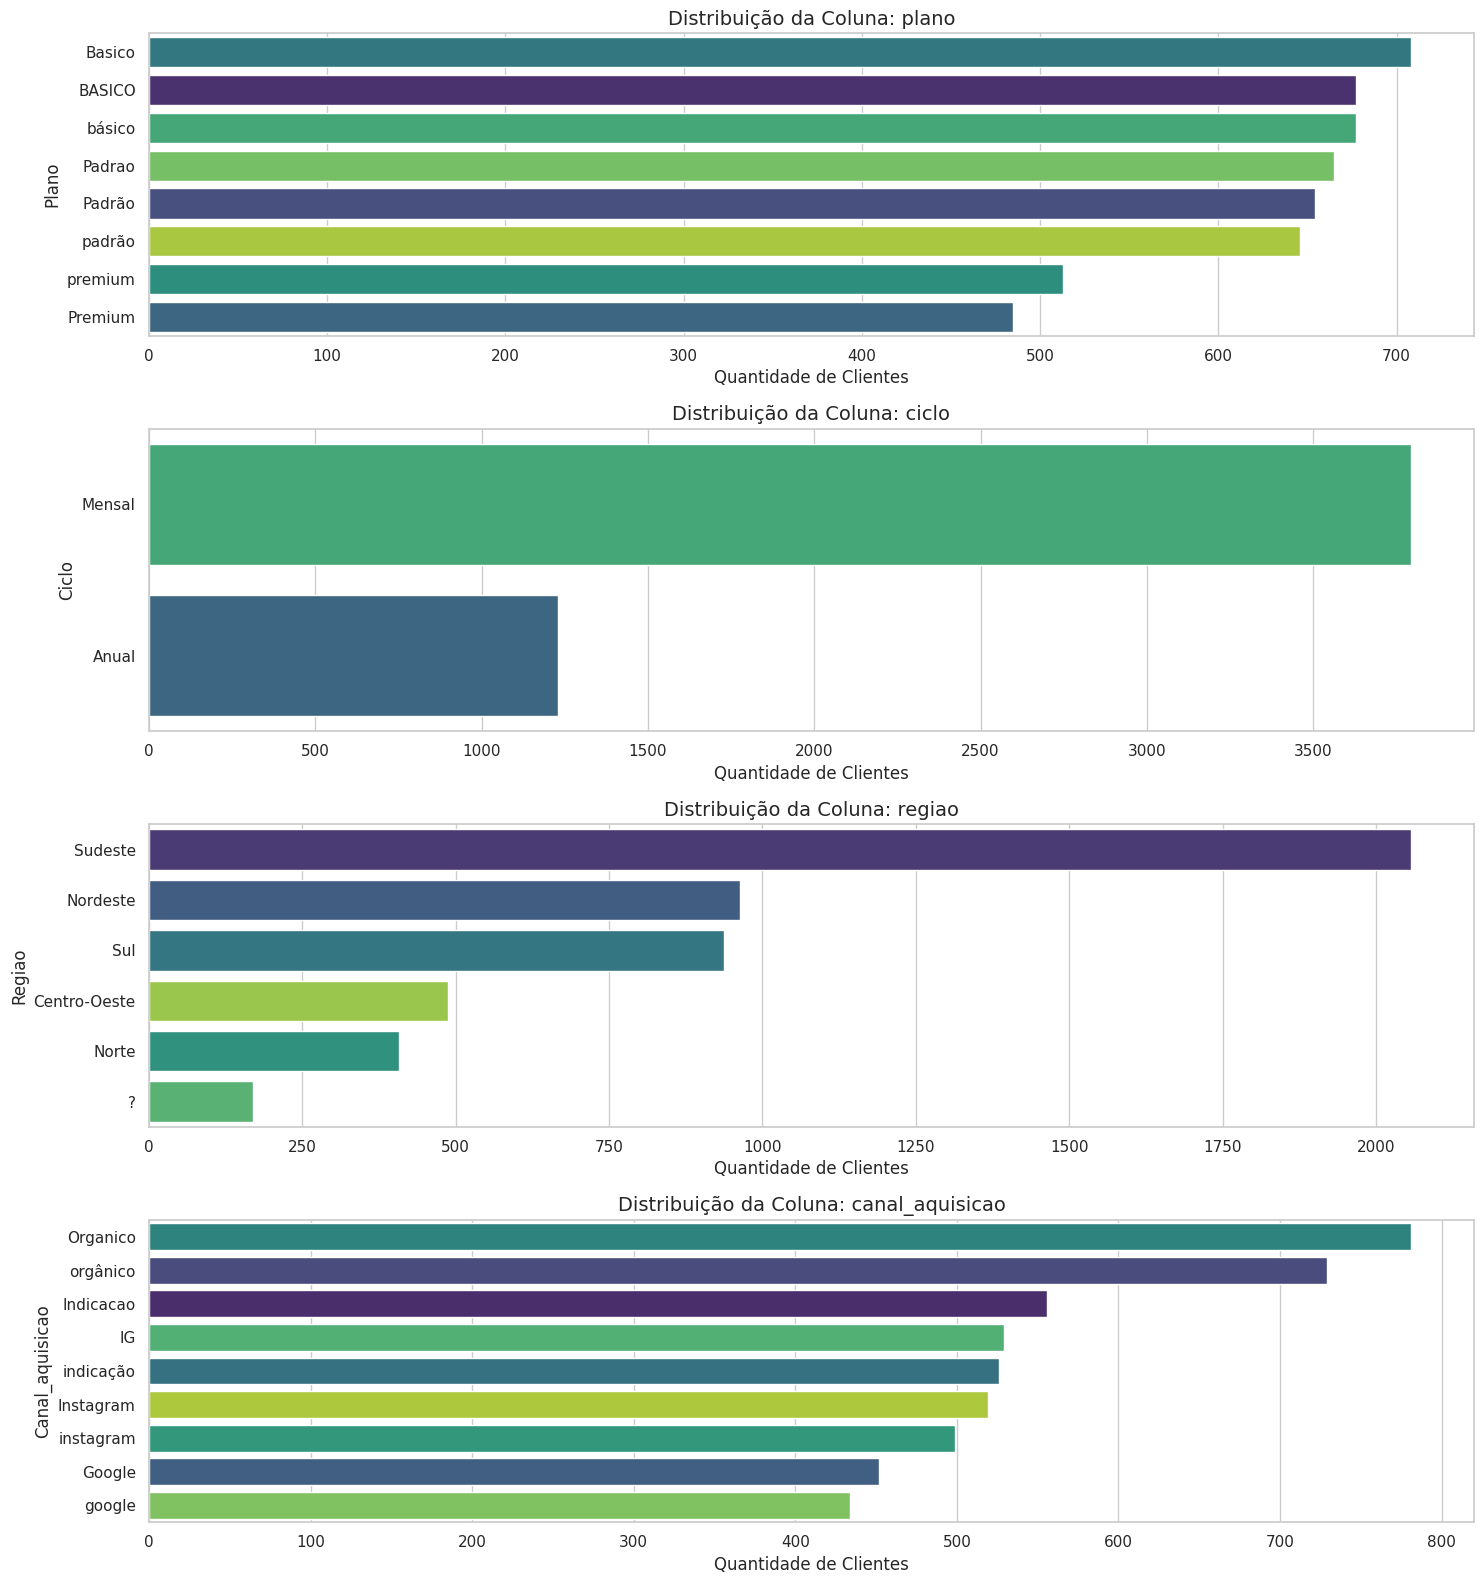

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Nova lista de colunas, excluindo 'motivo_cancelamento'
colunas_analise_reduzida = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Configurando o estilo e dimensões dos gráficos
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 16))

for i, col in enumerate(colunas_analise_reduzida, 1):
    # 1. Contagem de valores (incluindo nulos, se houver)
    contagem = df[col].value_counts(dropna=False)

    print(f"\n=== Distribuição da coluna: {col} ===")
    print(contagem)

    # 2. Criação do gráfico de barras
    plt.subplot(4, 1, i)
    df_temp = df[col].fillna('Nulo/Não Informado')

    sns.countplot(y=df_temp, order=df_temp.value_counts().index, palette='viridis', hue=df_temp, legend=False)
    plt.title(f"Distribuição da Coluna: {col}", fontsize=14)
    plt.xlabel("Quantidade de Clientes", fontsize=12)
    plt.ylabel(col.capitalize(), fontsize=12)

plt.tight_layout()
plt.show()

### Análise de Nulos e Limpeza de Dados

In [4]:
nulos_por_coluna = df.isnull().sum()
print(nulos_por_coluna)

cliente_id                   0
idade                        0
plano                        0
ciclo                        0
valor_mensal                 0
regiao                       0
canal_aquisicao              0
nps                          0
data_assinatura              0
data_cancelamento         3509
data_ultimo_acesso          50
data_extracao                0
dias_ativos_ult_mes          0
horas_assistidas_total       0
motivo_cancelamento       3509
churn                        0
dtype: int64


### Tratamento de Valores "?"

In [5]:
df_regiao_interrogacao = df[df['regiao'] == '?']
display(df_regiao_interrogacao.head())

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0


### Padronização das colunas `plano` e `canal_aquisicao`

In [6]:
# 3. Padronização da coluna plano
mapeamento_plano = {
    'Basico': 'básico',
    'BASICO': 'básico',
    'básico': 'básico',
    'Padrao': 'padrão',
    'Padrão': 'padrão',
    'padrão': 'padrão',
    'Premium': 'premium',
    'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano)

# 4. Padronização da coluna canal_aquisicao
mapeamento_canal = {
    'Organico': 'orgânico',
    'orgânico': 'orgânico',
    'Indicacao': 'indicação',
    'indicação': 'indicação',
    'IG': 'instagram',
    'Instagram': 'instagram',
    'instagram': 'instagram',
    'Google': 'google',
    'google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].map(mapeamento_canal)

# Exibindo os novos valores únicos para validação
print("--- Novos valores únicos para plano ---")
print(df['plano'].value_counts())

print("\n--- Novos valores únicos para canal_aquisicao ---")
print(df['canal_aquisicao'].value_counts())

--- Novos valores únicos para plano ---
plano
básico     2062
padrão     1965
premium     998
Name: count, dtype: int64

--- Novos valores únicos para canal_aquisicao ---
canal_aquisicao
instagram    1547
orgânico     1510
indicação    1082
google        886
Name: count, dtype: int64


### Substituição de Valores "?" por Nulo (NaN)

In [7]:
import numpy as np

# Substituindo '?' por NaN (Not a Number)
df = df.replace('?', np.nan)

# Verificando a nova contagem de nulos nas colunas que antes tinham interrogações
print("--- Quantidade de nulos atualizada por coluna ---")
print(df.isnull().sum())

print("\n--- Verificando se ainda existem interrogações na coluna 'regiao' ---")
print(f"Quantidade de '?': {(df['regiao'] == '?').sum()}")

--- Quantidade de nulos atualizada por coluna ---
cliente_id                   0
idade                        0
plano                        0
ciclo                        0
valor_mensal                 0
regiao                     170
canal_aquisicao              0
nps                          0
data_assinatura              0
data_cancelamento         3509
data_ultimo_acesso          50
data_extracao                0
dias_ativos_ult_mes          0
horas_assistidas_total       0
motivo_cancelamento       3509
churn                        0
dtype: int64

--- Verificando se ainda existem interrogações na coluna 'regiao' ---
Quantidade de '?': 0


### Coversão de Colunas de Data para Datetime

In [8]:
# Lista das colunas de data identificadas no DataFrame
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Convertendo cada uma para o tipo datetime do pandas
for col in colunas_data:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Verificando a alteração nos tipos de dados
print("--- Tipos das colunas após conversão ---")
df.info()

--- Tipos das colunas após conversão ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   cliente_id              5025 non-null   int64         
 1   idade                   5025 non-null   int64         
 2   plano                   5025 non-null   object        
 3   ciclo                   5025 non-null   object        
 4   valor_mensal            5025 non-null   float64       
 5   regiao                  4855 non-null   object        
 6   canal_aquisicao         5025 non-null   object        
 7   nps                     5025 non-null   int64         
 8   data_assinatura         5025 non-null   datetime64[ns]
 9   data_cancelamento       1516 non-null   datetime64[ns]
 10  data_ultimo_acesso      4975 non-null   datetime64[ns]
 11  data_extracao           5025 non-null   datetime64[ns]
 12  dias_at

### Criação de Colunas de Diferença de Datas

In [9]:
# Calculando a diferença em dias entre as combinações de datas

# 1. Da assinatura até o cancelamento (para quem cancelou)
df['dias_assinatura_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

# 2. Da assinatura até o último acesso
df['dias_assinatura_ate_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days

# 3. Do último acesso até o cancelamento
df['dias_ultimo_acesso_ate_cancelamento'] = (df['data_cancelamento'] - df['data_ultimo_acesso']).dt.days

# 4. Da assinatura até a data de extração
df['dias_assinatura_ate_extracao'] = (df['data_extracao'] - df['data_assinatura']).dt.days

# 5. Do último acesso até a data de extração
df['dias_ultimo_acesso_ate_extracao'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 6. Do cancelamento até a data de extração
df['dias_cancelamento_ate_extracao'] = (df['data_extracao'] - df['data_cancelamento']).dt.days

# 7. Do último acesso até o cancelamento (especificado pelo usuário)
df['dias_ultimo_acesso_ate_cancelamento'] = (df['data_cancelamento'] - df['data_ultimo_acesso']).dt.days

# Visualizando as novas colunas criadas
colunas_novas = [
    'cliente_id',
    'dias_assinatura_ate_cancelamento',
    'dias_assinatura_ate_ultimo_acesso',
    'dias_ultimo_acesso_ate_cancelamento',
    'dias_assinatura_ate_extracao',
    'dias_ultimo_acesso_ate_extracao',
    'dias_cancelamento_ate_extracao'
]

display(df[colunas_novas].head())

,cliente_id,dias_assinatura_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_extracao,dias_ultimo_acesso_ate_extracao,dias_cancelamento_ate_extracao
0,5746,NaN,293.0,NaN,295,2.0,NaN
1,4100,NaN,607.0,NaN,608,1.0,NaN
2,4690,607.0,590.0,17.0,1047,457.0,440.0
3,3454,NaN,286.0,NaN,304,18.0,NaN
4,1437,NaN,270.0,NaN,285,15.0,NaN


### Sanity Check nas Colunas de Diferença de Datas

In [10]:
# 1. Resumo estatístico para checar amplitudes (min, max, médias)
colunas_diferenca = [
    'dias_assinatura_ate_cancelamento',
    'dias_assinatura_ate_ultimo_acesso',
    'dias_ultimo_acesso_ate_cancelamento',
    'dias_assinatura_ate_extracao',
    'dias_ultimo_acesso_ate_extracao',
    'dias_cancelamento_ate_extracao'
]

print("=== Resumo Estatístico das Diferenças (em dias) ===")
display(df[colunas_diferenca].describe())

# 2. Verificação de valores negativos (inconsistências cronológicas)
print("\n=== Verificação de Valores Negativos (Erros Cronológicos) ===")
for col in colunas_diferenca:
    negativos = (df[col] < 0).sum()
    print(f"Coluna '{col}': {negativos} valores negativos")

# 3. Validação lógica para quem cancelou vs quem não cancelou (churn)
print("\n=== Validação de Coerência com Churn (Cancelados) ===")
print(f"Total de clientes com Churn=1: {df[df['churn'] == 1].shape[0]}")
print(f"Valores preenchidos em 'dias_assinatura_ate_cancelamento': {df['dias_assinatura_ate_cancelamento'].notnull().sum()}")
print(f"Valores preenchidos em 'dias_ultimo_acesso_ate_cancelamento': {df['dias_ultimo_acesso_ate_cancelamento'].notnull().sum()}")

=== Resumo Estatístico das Diferenças (em dias) ===


,dias_assinatura_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_extracao,dias_ultimo_acesso_ate_extracao,dias_cancelamento_ate_extracao
count,1516.000000,4975.000000,1501.000000,5025.000000,4975.000000,1516.000000
mean,220.407652,372.186533,21.000666,412.432040,40.451859,79.694591
std,145.004268,277.107592,10.783104,270.382969,55.107192,67.851077
min,11.000000,-47.000000,3.000000,1.000000,0.000000,3.000000
25%,118.000000,163.000000,12.000000,213.000000,10.000000,30.000000
50%,182.500000,307.000000,21.000000,349.000000,20.000000,60.500000
75%,288.500000,512.000000,30.000000,549.000000,44.000000,107.250000
max,1067.000000,1809.000000,137.000000,1815.000000,469.000000,440.000000



=== Verificação de Valores Negativos (Erros Cronológicos) ===
Coluna 'dias_assinatura_ate_cancelamento': 0 valores negativos
Coluna 'dias_assinatura_ate_ultimo_acesso': 1 valores negativos
Coluna 'dias_ultimo_acesso_ate_cancelamento': 0 valores negativos
Coluna 'dias_assinatura_ate_extracao': 0 valores negativos
Coluna 'dias_ultimo_acesso_ate_extracao': 0 valores negativos
Coluna 'dias_cancelamento_ate_extracao': 0 valores negativos

=== Validação de Coerência com Churn (Cancelados) ===
Total de clientes com Churn=1: 1516
Valores preenchidos em 'dias_assinatura_ate_cancelamento': 1516
Valores preenchidos em 'dias_ultimo_acesso_ate_cancelamento': 1501


### Verificação após o filtro

In [11]:
# 1. Identificar apenas as colunas numéricas (inteiros e floats)
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("=== Colunas Numéricas Identificadas ===")
print(colunas_numericas)

# 2. Retornar as estatísticas descritivas básicas dessas colunas
print("\n=== Estatísticas das Colunas Numéricas ===")
display(df[colunas_numericas].describe())

# 3. Contar quantos valores nulos existem em cada uma dessas colunas
print("\n=== Quantidade de Nulos nas Colunas Numéricas ===")
nulos_numericas = df[colunas_numericas].isnull().sum()
display(nulos_numericas)

=== Colunas Numéricas Identificadas ===
['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'dias_assinatura_ate_cancelamento', 'dias_assinatura_ate_ultimo_acesso', 'dias_ultimo_acesso_ate_cancelamento', 'dias_assinatura_ate_extracao', 'dias_ultimo_acesso_ate_extracao', 'dias_cancelamento_ate_extracao']

=== Estatísticas das Colunas Numéricas ===


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,dias_assinatura_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_extracao,dias_ultimo_acesso_ate_extracao,dias_cancelamento_ate_extracao
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,4975.000000,1501.000000,5025.000000,4975.000000,1516.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,372.186533,21.000666,412.432040,40.451859,79.694591
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,277.107592,10.783104,270.382969,55.107192,67.851077
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,-47.000000,3.000000,1.000000,0.000000,3.000000
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,163.000000,12.000000,213.000000,10.000000,30.000000
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,307.000000,21.000000,349.000000,20.000000,60.500000
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,512.000000,30.000000,549.000000,44.000000,107.250000
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,1809.000000,137.000000,1815.000000,469.000000,440.000000



=== Quantidade de Nulos nas Colunas Numéricas ===


,0
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
dias_assinatura_ate_cancelamento,3509
dias_assinatura_ate_ultimo_acesso,50
dias_ultimo_acesso_ate_cancelamento,3524


In [12]:
# Criando um novo DataFrame filtrando para manter apenas valores positivos, zero ou nulos
df_filtrado = df[(df['dias_assinatura_ate_ultimo_acesso'] >= 0) | (df['dias_assinatura_ate_ultimo_acesso'].isnull())].copy()

# Verificando o resultado
print(f"Tamanho do DataFrame original: {df.shape[0]} linhas")
print(f"Tamanho do novo DataFrame (filtrado): {df_filtrado.shape[0]} linhas")

# Verificação rápida se ainda há negativos
negativos_restantes = (df_filtrado['dias_assinatura_ate_ultimo_acesso'] < 0).sum()
print(f"Quantidade de valores negativos restantes: {negativos_restantes}")

Tamanho do DataFrame original: 5025 linhas
Tamanho do novo DataFrame (filtrado): 5024 linhas
Quantidade de valores negativos restantes: 0


## Colunas Numéricas

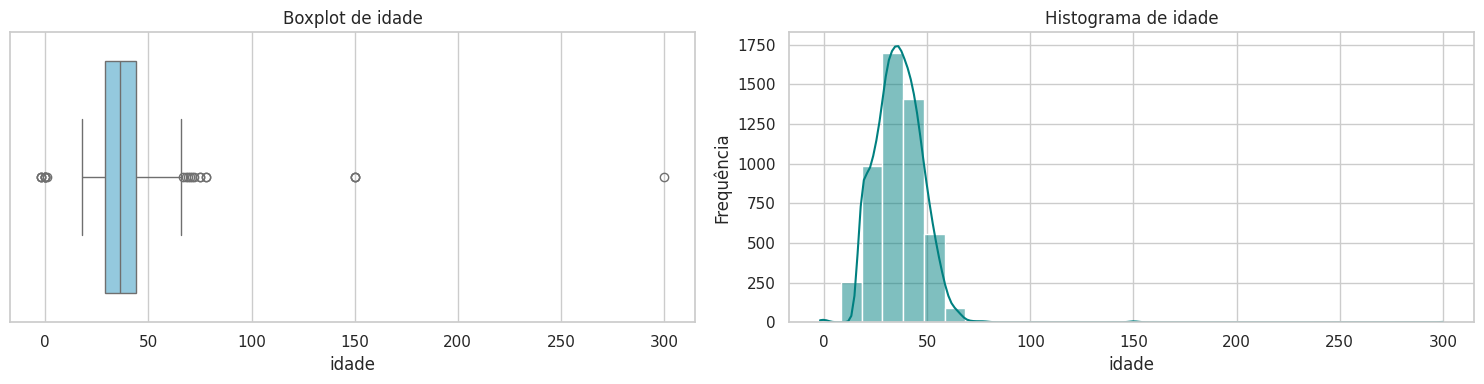

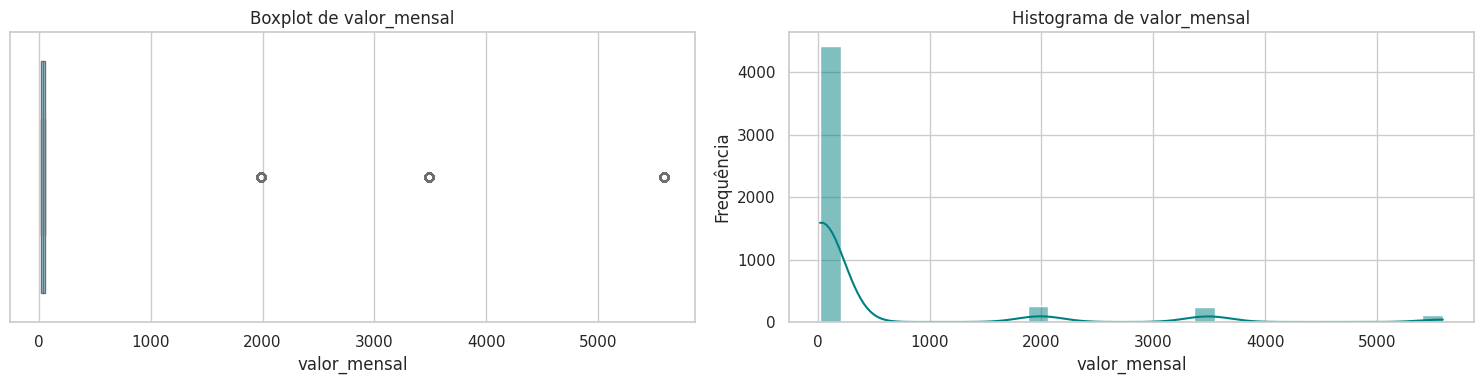

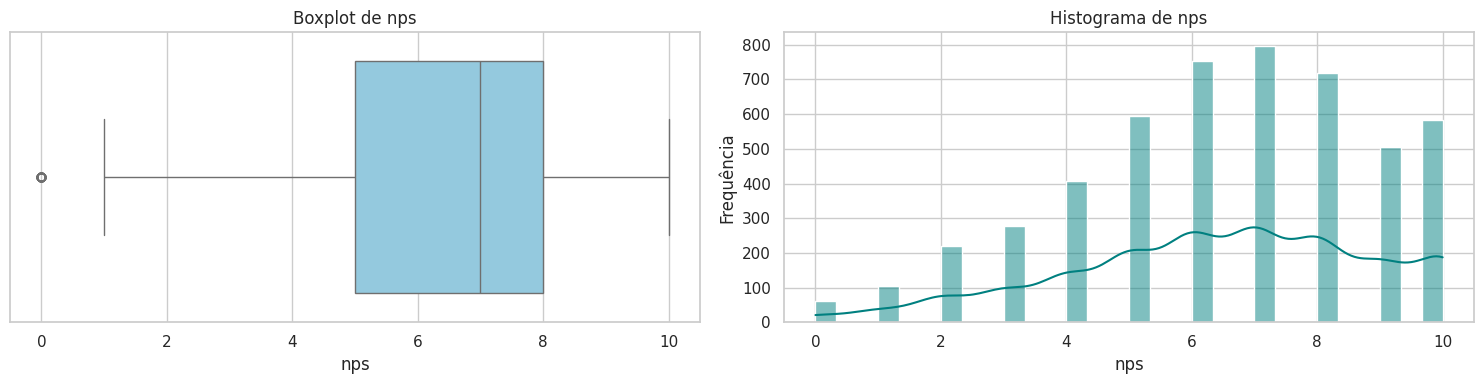

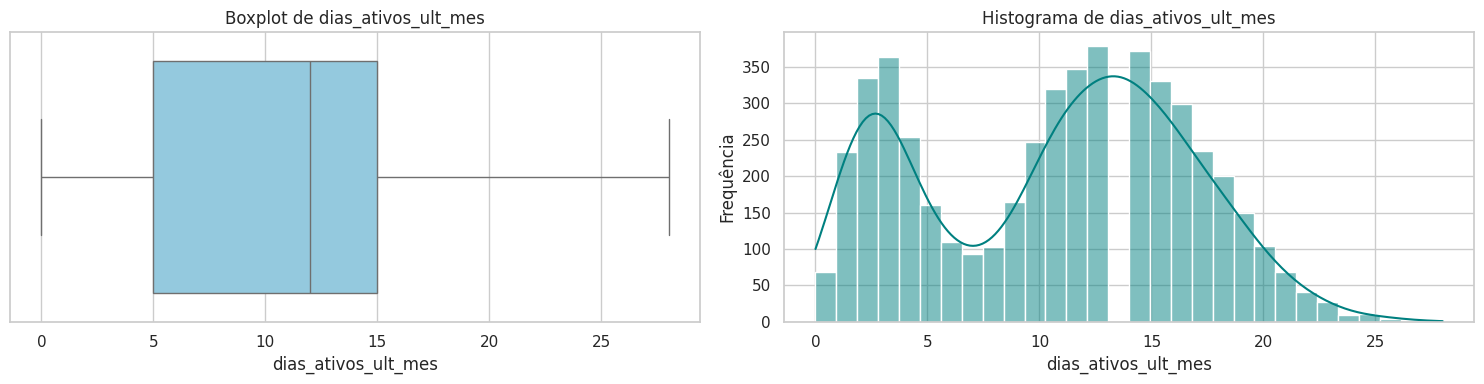

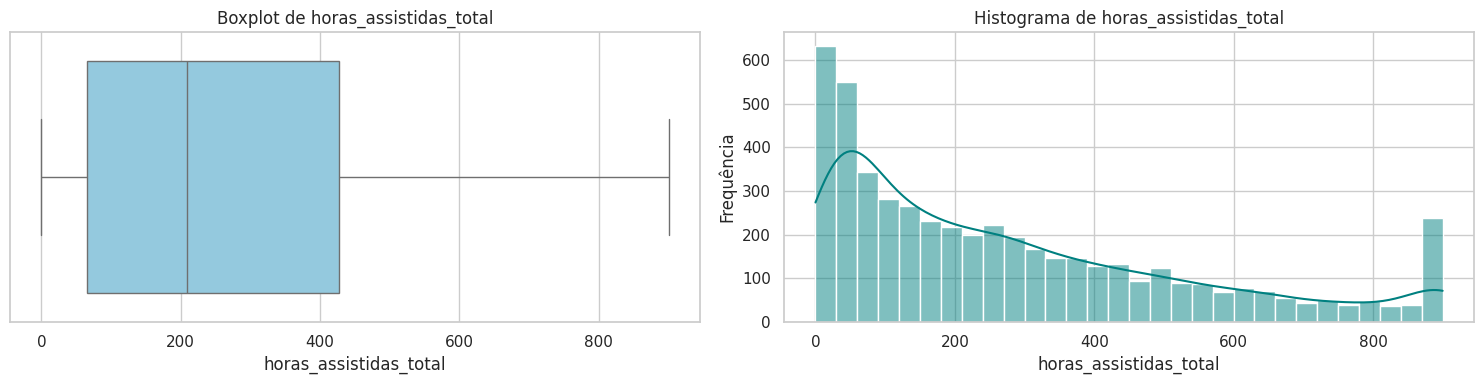

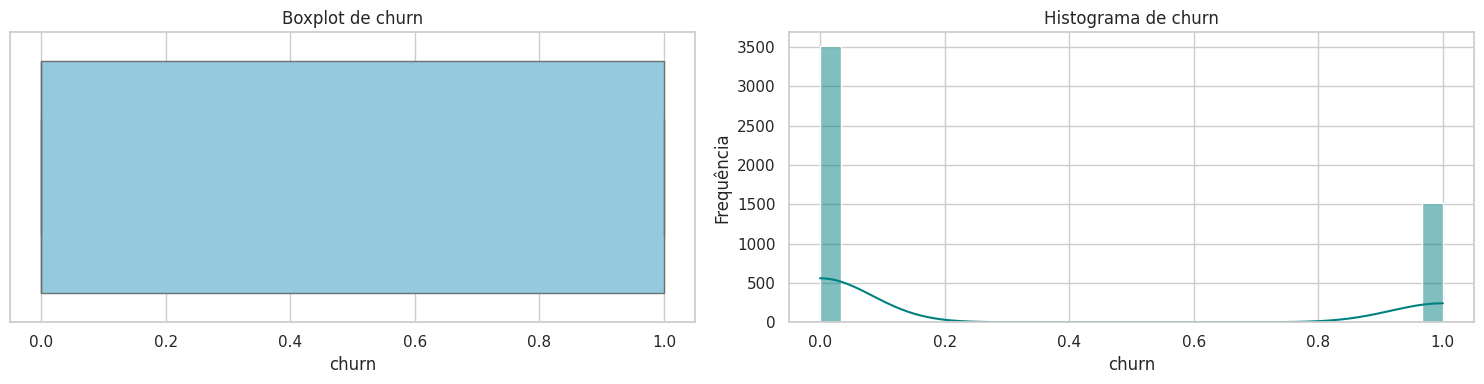

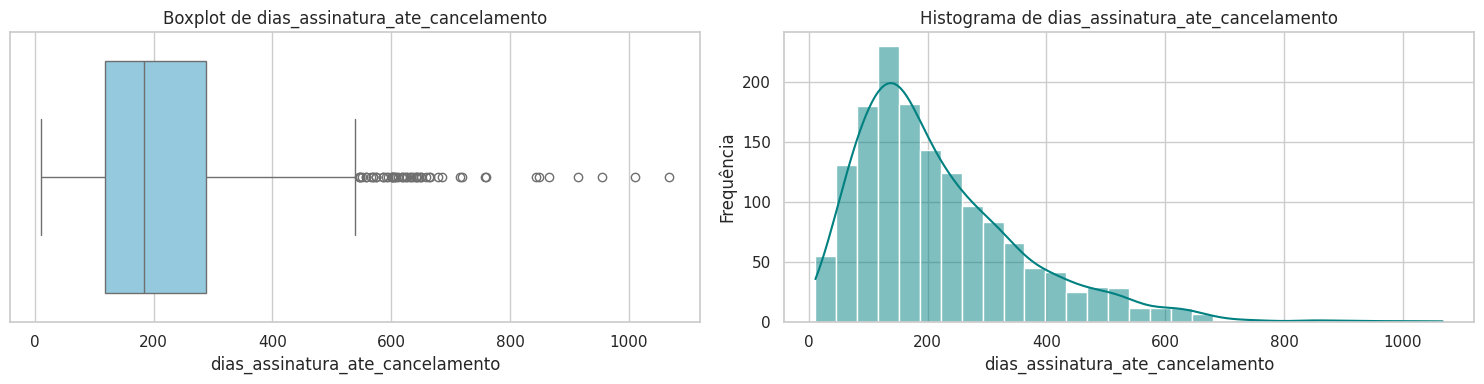

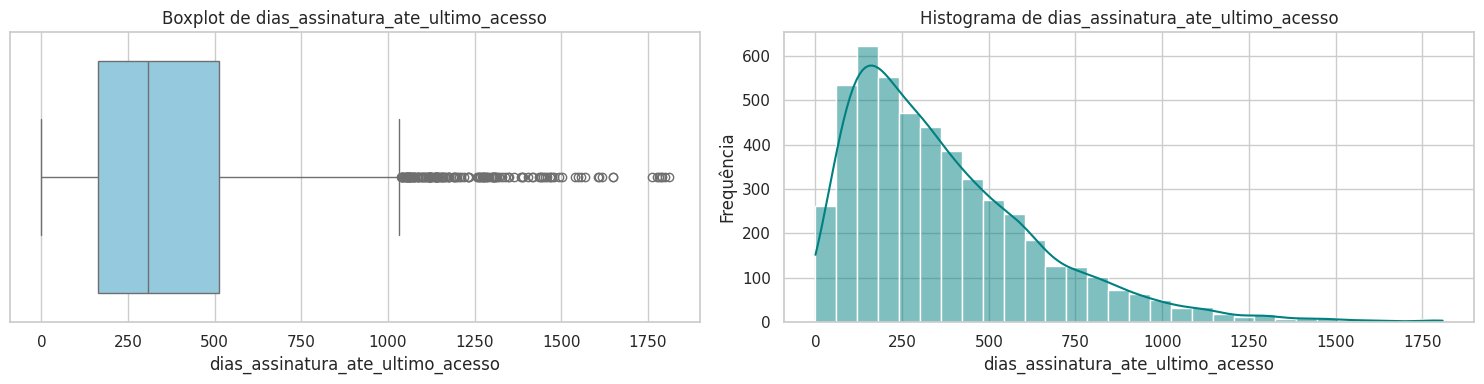

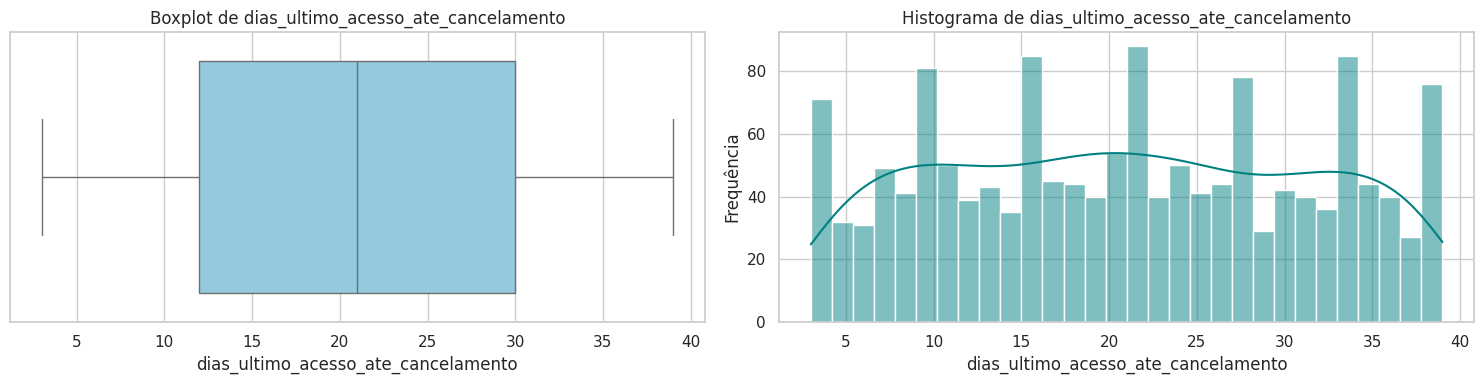

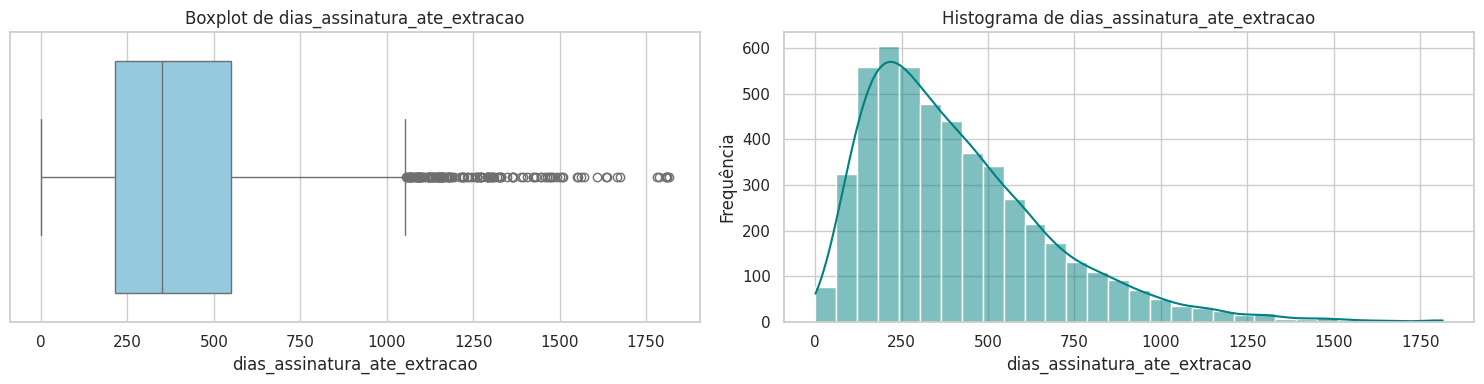

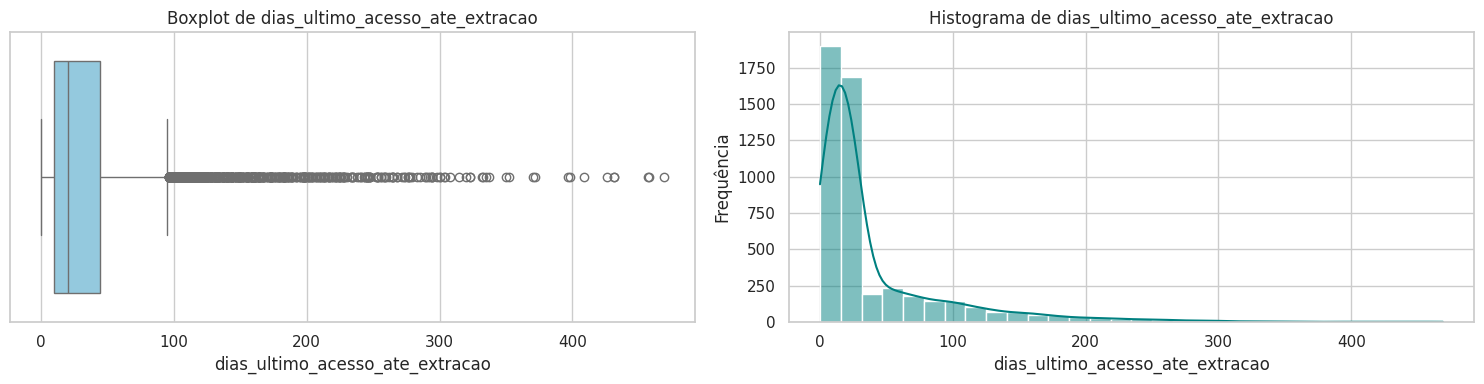

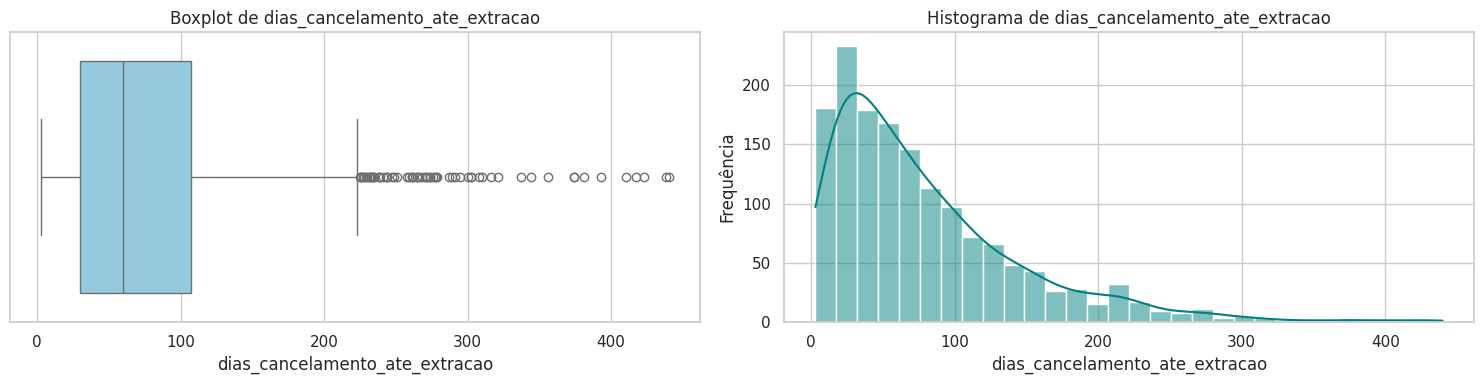

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista das colunas numéricas excluindo 'cliente_id'
colunas_plot = [col for col in colunas_numericas if col != 'cliente_id']

# Configura o estilo dos gráficos
sns.set_theme(style="whitegrid")

# Para cada coluna, gera um boxplot e um histograma lado a lado
for col in colunas_plot:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # 1. Boxplot
    sns.boxplot(x=df_filtrado[col], ax=axes[0], color='skyblue')
    axes[0].set_title(f'Boxplot de {col}')
    axes[0].set_xlabel(col)

    # 2. Histograma
    sns.histplot(df_filtrado[col], ax=axes[1], kde=True, color='teal', bins=30)
    axes[1].set_title(f'Histograma de {col}')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Frequência')

    plt.tight_layout()
    plt.show()

In [14]:
# Filtrando o DataFrame para manter apenas idades entre 18 e 90 anos
linhas_antes = df_filtrado.shape[0]
df_filtrado = df_filtrado[(df_filtrado['idade'] >= 18) & (df_filtrado['idade'] <= 90)].copy()
linhas_depois = df_filtrado.shape[0]

print(f"Linhas antes do filtro de idade: {linhas_antes}")
print(f"Linhas após o filtro de idade (18 a 90 anos): {linhas_depois}")
print(f"Total de linhas removidas: {linhas_antes - linhas_depois}")

# Exibindo resumo rápido da coluna idade após o filtro
display(df_filtrado['idade'].describe())

Linhas antes do filtro de idade: 5024
Linhas após o filtro de idade (18 a 90 anos): 5011
Total de linhas removidas: 13


,idade
count,5011.000000
mean,36.272401
std,10.615144
min,18.000000
25%,29.000000
50%,36.000000
75%,44.000000
max,78.000000


In [15]:
# Filtrando e exibindo as linhas onde o valor_mensal é maior que 1000
clientes_valor_alto = df_filtrado[df_filtrado['valor_mensal'] > 1000]

print(f"Quantidade de registros com valor mensal > 1000: {len(clientes_valor_alto)}")
display(clientes_valor_alto)

Quantidade de registros com valor mensal > 1000: 602


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_extracao,dias_ultimo_acesso_ate_extracao,dias_cancelamento_ate_extracao
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,286.0,NaN,304,18.0,NaN
14,5581,18,padrão,Mensal,3490.0,Sudeste,orgânico,7,2023-07-22,NaT,...,15,160.7,NaN,0,NaN,189.0,NaN,193,4.0,NaN
29,5979,31,padrão,Mensal,3490.0,Sudeste,instagram,10,2023-08-22,NaT,...,14,117.2,NaN,0,NaN,134.0,NaN,162,28.0,NaN
34,1433,56,padrão,Anual,3490.0,NaN,orgânico,9,2023-04-14,NaT,...,11,180.4,NaN,0,NaN,283.0,NaN,292,9.0,NaN
42,4776,61,básico,Anual,1990.0,Sudeste,orgânico,4,2023-10-01,2023-12-15,...,6,47.8,problema tecnico,1,75.0,55.0,20.0,122,67.0,47.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,padrão,Anual,3490.0,Sudeste,indicação,7,2020-12-01,NaT,...,20,900.0,NaN,0,NaN,1138.0,NaN,1156,18.0,NaN
4991,2396,23,padrão,Anual,3490.0,Nordeste,orgânico,8,2021-04-14,NaT,...,18,900.0,NaN,0,NaN,1017.0,NaN,1022,5.0,NaN
5000,5926,37,padrão,Anual,3490.0,Centro-Oeste,orgânico,10,2022-12-01,NaT,...,9,243.6,NaN,0,NaN,402.0,NaN,426,24.0,NaN
5006,4388,18,básico,Anual,1990.0,Nordeste,instagram,9,2023-05-03,NaT,...,11,160.6,NaN,0,NaN,251.0,NaN,273,22.0,NaN


In [16]:
# Contando os valores distintos da coluna valor_mensal e suas respectivas frequências
valores_distintos = df_filtrado['valor_mensal'].value_counts()

print(f"Quantidade de valores distintos em 'valor_mensal': {len(valores_distintos)}")
print("\nFrequência de cada valor:")
display(valores_distintos)

Quantidade de valores distintos em 'valor_mensal': 6

Frequência de cada valor:


,count
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104


In [17]:
# Corrigindo os valores acima de 1900 dividindo-os por 100
df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] /= 100
df.loc[df['valor_mensal'] > 1900, 'valor_mensal'] /= 100

# Verificando a nova contagem de valores distintos após o ajuste
valores_distintos_corrigidos = df_filtrado['valor_mensal'].value_counts()
print("=== Valores distintos corrigidos em 'valor_mensal' ===")
display(valores_distintos_corrigidos)

=== Valores distintos corrigidos em 'valor_mensal' ===


,count
valor_mensal,
19.9,2058
34.9,1958
55.9,995


## Criando Novas Variáveis

In [18]:
# 1. recencia = diferença entre a data de extração e a data do último acesso
df_filtrado['recencia'] = (df_filtrado['data_extracao'] - df_filtrado['data_ultimo_acesso']).dt.days
df['recencia'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 2. meses_assinatura = diferença entre data de cancelamento (ou data de extração, se cancelamento for nula) e data de assinatura, dividido por 30
data_final_filtrado = df_filtrado['data_cancelamento'].fillna(df_filtrado['data_extracao'])
df_filtrado['meses_assinatura'] = (data_final_filtrado - df_filtrado['data_assinatura']).dt.days / 30.0

data_final_df = df['data_cancelamento'].fillna(df['data_extracao'])
df['meses_assinatura'] = (data_final_df - df['data_assinatura']).dt.days / 30.0

# 3. receita_acumulada = valor_mensal multiplicado por meses_assinatura
df_filtrado['receita_acumulada'] = df_filtrado['valor_mensal'] * df_filtrado['meses_assinatura']
df['receita_acumulada'] = df['valor_mensal'] * df['meses_assinatura']

# Exibindo as primeiras linhas com as novas colunas para validação
colunas_novas_criadas = ['recencia', 'meses_assinatura', 'receita_acumulada']
display(df_filtrado[['cliente_id', 'valor_mensal'] + colunas_novas_criadas].head())

,cliente_id,valor_mensal,recencia,meses_assinatura,receita_acumulada
0,5746,19.9,2.0,9.833333,195.683333
1,4100,34.9,1.0,20.266667,707.306667
2,4690,55.9,457.0,20.233333,1131.043333
3,3454,19.9,18.0,10.133333,201.653333
4,1437,19.9,15.0,9.500000,189.050000


In [19]:
# Estatísticas descritivas para as três novas colunas criadas
colunas_novas = ['recencia', 'meses_assinatura', 'receita_acumulada']

print("=== Estatísticas Descritivas das Novas Colunas ===")
display(df_filtrado[colunas_novas].describe())

=== Estatísticas Descritivas das Novas Colunas ===


,recencia,meses_assinatura,receita_acumulada
count,4961.000000,5011.000000,5011.000000
mean,40.452731,12.950376,428.914295
std,55.112223,9.186362,371.527653
min,0.000000,0.033333,0.663333
25%,10.000000,6.033333,168.585000
50%,20.000000,10.766667,321.080000
75%,44.000000,17.600000,570.033333
max,469.000000,60.500000,2893.756667


# Conclusões da univariada — variáveis categóricas
**1. Base suja**

  * `plano`: "Basico" / "BASICO" / "básico" são o mesmo plano, mas contam separado (708 + 677 + 677). O mesmo com Padrão (3 formas) e Premium (2 formas). Sem unificar, você teria 8 planos quando existem 3.
  * `canal_aquisicao`: pior ainda — 9 grafias para 4 canais. "Organico"/"orgânico", "Indicacao"/"indicação", "IG"/"Instagram"/"instagram", "Google"/"google".

**2.** O `?` na região é ausente disfarçado São 170 registros com "?", que o `isnull()` não pega porque é texto. Representa ~3,4% da base sem região informada. Tratá-lo como categoria válida criaria uma "região Interrogação" nos gráficos; o certo foi convertê-lo em nulo.

**3.** **Insight de negócio real — a base é fortemente concentrada no Sudeste**. Somando as regiões válidas: **Sudeste (2.057) sozinho é ~42%** da base, mais que Nordeste (964) e Sul (938) juntos parciais. Norte (408) e Centro-Oeste (488) são pequenos. Isso importa para qualquer análise regional depois — há Sudeste de sobra para conclusões robustas, mas Norte tem amostra pequena, então taxa de churn dessa região terá muito mais incerteza.

**4. Insight de negócio — o produto é predominantemente mensal. Mensal (3.794) contra Anual (1.231):** ~75% da base paga mês a mês.

**5. A distribuição dos canais é equilibrada — nenhum domina.** Depois de unificar: Orgânico (1.510), Instagram (1.547), Indicação (1.082), Google ( 886). Aquisição diversificada, sem dependência perigosa de um único canal. Saudável do ponto de vista de risco de aquisição.

# Análise Bivariada

### Filtrar a base para evitar vieses

Tamanho de df_filtrado: 5011 linhas
Tamanho de df_analise: 3668 linhas
Mínimo de dias de assinatura até extração no novo df: 220


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,churn,dias_assinatura_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_extracao,dias_ultimo_acesso_ate_extracao,dias_cancelamento_ate_extracao,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,0,NaN,293.0,NaN,295,2.0,NaN,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,0,NaN,607.0,NaN,608,1.0,NaN,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,1,607.0,590.0,17.0,1047,457.0,440.0,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,19.9,Sul,google,10,2023-04-02,NaT,...,0,NaN,286.0,NaN,304,18.0,NaN,18.0,10.133333,201.653333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,0,NaN,270.0,NaN,285,15.0,NaN,15.0,9.500000,189.050000


### Cuidados importantes com conclusões precipitadas

**dias_ativos_ult_mes** — Quem já deu churn não teve acesso nos últimos meses, então aparece zerado por definição — não porque usava pouco, mas porque já tinha saído.

**data_ultimo_acesso (e a recência derivada dela)** — Mesma contaminação. Para quem cancelou, o último acesso trava perto da data de saída, então a recência reflete o churn que já aconteceu, não um comportamento que o antecede. Serve para descrever engajamento entre ativos, mas como preditor de churn é enganosa

**horas_assistidas_total** — Viés parcial em 2 frentes. Primeiro, quem deu churn parou de assistir antes de sair, então acumula menos horas naturalmente, não é uma CAUSA do churn prévio. Segundo, é confundida pelo tempo de casa: veterano naturalmente acumula mais horas — legal ser normalizada por `meses_assinatura` para comparar de forma justa

**meses_assinatura** — entre os clientes maduros, quem permanece ativo tem mais tempo de casa acumulado do que quem cancelou, o que é esperado — cliente que não dá churn continua na base acumulando meses, enquanto o do churner congela no cancelamento. A leitura honesta é descritiva: os sobreviventes são, por natureza, mais antigos, e há um sinal real de que quem cancela tende a durar menos. Vale só a ressalva de não transformar isso diretamente numa regra preditiva ("abaixo de X meses = risco"), porque o tempo do churner está fechado e o do ativo ainda corre — a forma rigorosa de medir essa queda de permanência ao longo do tempo é a análise de cohort, que desdobra essa diferença agregada na curva de retenção mês a mês.

**tempo até o churn (data_cancelamento − data_assinatura)** — Só existe para quem deu churn (cancelamento é vazio nos ativos). Não entra em comparação churn vs não-churn; serve para entender quando o churn acontece — foi daí que saíram os 220 dias.

**tempo desde o último acesso até o cancelamento (data_cancelamento − data_ultimo_acesso)** — Também exclusiva de quem cancelou. Descreve o comportamento de saída, não entra em comparação churn vs não-churn

**Qualquer diferença que envolva `data_ultimo_acesso` ou `data_cancelamento`** carrega o churn dentro dela, porque essas duas datas são marcadas pelo próprio desfecho.

As diferenças "limpas" para entender padrão churn x não churn são as que dependem só de `data_assinatura` e `data_extracao` (a maturidade) — e mesmo essa exige o corte para não enganar.

## Conclusões análise bivariada

Aqui estão os insights só da bivariada, com os números do notebook (recorte maduro, ≥220 dias):

Premissa: análise feita sobre clientes com pelo menos 220 dias de assinatura — o recorte que garante que a pessoa teve tempo real de dar churn.

1. NPS é o sinal mais forte E é um sinal honesto: o NPS é declarado ao longo da relação, não é consequência mecânica do churn. É a primeira candidata a virar alerta precoce de cancelamento.

2. Idade e valor do plano praticamente não separam. Idade idêntica nos dois grupos (36 vs 36) e valor mensal consequencia do plano básico x premium. É um achado útil: descarta hipóteses óbvias e evita que o time gaste energia segmentando por essas variáveis.

3. Ciclo e região. Anual e mensal têm composição praticamente igual entre churners e não-churners, e a região, vemos maior diferença de churn no Norte e Centro-oeste. O caso do ciclo é contraintuitivo — o compromisso do plano anual não está segurando ninguém de forma perceptível. (Vale lembrar que 75% da base é mensal, o que reduz o contraste possível.)

4. Canal de aquisição tem efeito leve, mas com valor de negócio. Quem vem de indicação retém um pouco mais do que quem vem do google e outros canais. Conecta com decisão de marketing: a origem do cliente carrega alguma informação sobre a fidelidade dele — canais diferentes trazem clientes com propensões diferentes.

5. As variáveis de engajamento PARECEM separar espetacularmente — armadilha. Dias ativos (14 vs 3), horas assistidas (449 vs 73) e recência (15 vs 130 dias) mostram as maiores diferenças de toda a análise. Mas são contaminadas por vazamento de target: a pessoa parou de usar porque saiu, não o contrário *churn causa a variável, não o contrário). A separação é quase circular — elas descrevem o churn que já aconteceu, não o antecipam. Usá-las como "causa" seria o erro mais caro da análise.

# Frameworks de análise

## Framework 1 — Análise de Cohort (retenção)

* Há **indício de que a retenção piorou nas safras recentes** — as curvas de 2023 caem visivelmente mais rápido que as de 2022, que caem mais rápido que as de 2021. Isso é um sinal de negócio importante: a qualidade da aquisição ou a experiência do produto pode estar se deteriorando.

### Framework 2 — RFM adaptado a streaming

### Framework 3 — Pareto dos motivos de cancelamento

### Framework 4 — Funil de onboarding